# Experiment 1 — Let the Data Speak
## Monte Carlo: When does machine learning improve prediction?
五种数据生成过程，比较相同样本外测试集上的预测能力。训练、验证、测试严格分离。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import ParameterGrid
from sklearn.base import clone
from sklearn.metrics import mean_squared_error as mse
from sklearn.exceptions import ConvergenceWarning
import warnings
warnings.filterwarnings('ignore', category=ConvergenceWarning)
SEED=2026
N_TRAIN,N_VAL,N_TEST=300,150,500
N_REP=5 # 正式实验可增加到100


## 1. Data-generating processes
独立标准正态变量及噪声，$Y=g(X)+\sigma\epsilon$。

| 情形 | 信号 | 噪声标准差 |
|---|---|---|
| Linear | $X_1$ | 1 |
| Nonlinear | $(X_1^2-1)/\sqrt{2}$ | 1 |
| Interaction | $X_1X_2$ | 1 |
| Low SNR | $X_1$ | 5 |
| Weak signals | $\sum_{j=1}^{100}X_j/10$ | 1 |

前四种有10个预测变量，第五种有100个。信号方差均为1。这里是独立样本实验，不模拟金融时间序列依赖。

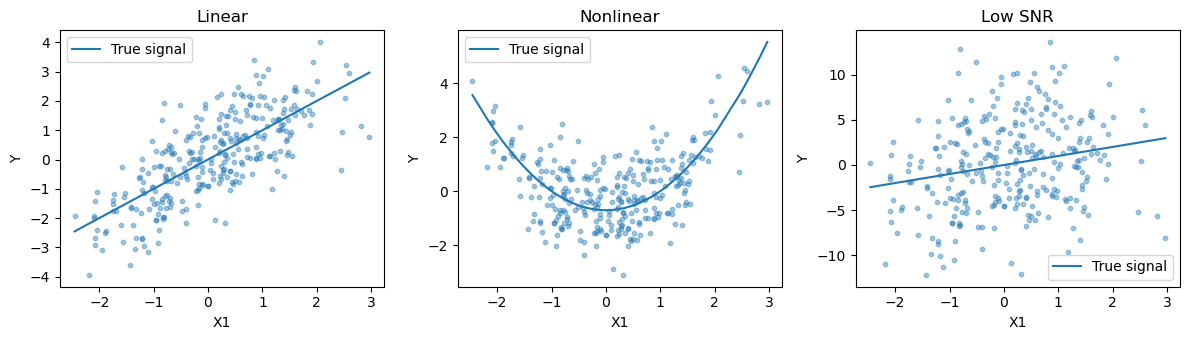

In [2]:
SCENARIOS=['Linear','Nonlinear','Interaction','Low SNR','Weak signals']
def generate(s,n,rng):
    p=100 if s=='Weak signals' else 10
    X=rng.normal(size=(n,p))
    if s in ['Linear','Low SNR']: g=X[:,0]
    elif s=='Nonlinear': g=(X[:,0]**2-1)/np.sqrt(2)
    elif s=='Interaction': g=X[:,0]*X[:,1]
    else: g=X.sum(axis=1)/np.sqrt(p)
    return X,g+(5 if s=='Low SNR' else 1)*rng.normal(size=n),g
fig,axes=plt.subplots(1,3,figsize=(12,3.5))
for ax,s in zip(axes,['Linear','Nonlinear','Low SNR']):
    X,y,g=generate(s,300,np.random.default_rng(SEED))
    k=np.argsort(X[:,0]); ax.scatter(X[:,0],y,s=10,alpha=.4); ax.plot(X[k,0],g[k],label='True signal'); ax.set(title=s,xlabel='X1',ylabel='Y'); ax.legend()
plt.tight_layout(); plt.show()

## 2. Prediction toolbox
验证集选择超参数；标准化、降维均在训练集内部拟合。选择后合并训练和验证集重新估计。额外加入知道前两个变量位置的二次 OLS 作为结构知识对照，而非公平的自动发现结构竞争者。

In [3]:
def toolbox(seed):
    return {
    'OLS':(make_pipeline(StandardScaler(),LinearRegression()),{}),
    'Ridge':(make_pipeline(StandardScaler(),Ridge()),{'ridge__alpha':[1,30,300]}),
    'Lasso':(make_pipeline(StandardScaler(),Lasso(max_iter=3000)),{'lasso__alpha':[.01,.05,.2]}),
    'Elastic Net':(make_pipeline(StandardScaler(),ElasticNet(max_iter=3000)),{'elasticnet__alpha':[.01,.1],'elasticnet__l1_ratio':[.2,.8]}),
    'PCR':(make_pipeline(StandardScaler(),PCA(random_state=seed),LinearRegression()),{'pca__n_components':[1,5,10]}),
    'PLS':(make_pipeline(StandardScaler(),PLSRegression(scale=False)),{'plsregression__n_components':[1,3,5]}),
    'Random Forest':(RandomForestRegressor(n_estimators=40,random_state=seed,n_jobs=1),{'max_depth':[3,8],'max_features':[.5,1.]}),
    'Gradient Boosting':(GradientBoostingRegressor(n_estimators=60,random_state=seed),{'max_depth':[1,3],'learning_rate':[.05,.1]}),
    'Neural Network':(make_pipeline(StandardScaler(),MLPRegressor(random_state=seed,max_iter=200)),{'mlpregressor__hidden_layer_sizes':[(16,),(32,16)],'mlpregressor__alpha':[.01,.1]})}
def fit_select(est,grid,Xtr,ytr,Xv,yv):
    best_loss=np.inf
    for params in ParameterGrid(grid):
        model=clone(est).set_params(**params).fit(Xtr,ytr)
        loss=mse(yv,model.predict(Xv).ravel())
        if loss<best_loss: best_loss,best=loss,params
    return clone(est).set_params(**best).fit(np.vstack([Xtr,Xv]),np.r_[ytr,yv])

## 3. Out-of-sample evaluation
$$R^2_{OS}=1-\frac{\sum_{test}(y_i-\hat y_i)^2}{\sum_{test}(y_i-\bar y_{train+val})^2}.$$
正值表示战胜历史均值。Oracle 使用真实信号，仅为参照。另计算信号估计误差 $\mathrm{MSE}_g=\frac1{n_{test}}\sum_i(\hat y_i-g(X_i))^2$。

In [4]:
def run_once(s,rep):
    seed=SEED+rep
    X,y,g=generate(s,N_TRAIN+N_VAL+N_TEST,np.random.default_rng(seed))
    a,b=N_TRAIN,N_TRAIN+N_VAL
    Xtr,Xv,Xte=X[:a],X[a:b],X[b:]; ytr,yv,yte=y[:a],y[a:b],y[b:]
    base=np.full(len(yte),y[:b].mean()); base_mse=mse(yte,base)
    rows=[]
    def record(name,pred):
        pred=np.asarray(pred).ravel(); loss=mse(yte,pred)
        rows.append(dict(scenario=s,rep=rep,model=name,MSE=loss,R2_OS=1-loss/base_mse,Signal_MSE=mse(g[b:],pred)))
    record('Historical Average',base); record('Oracle',g[b:])
    for name,(est,grid) in toolbox(seed).items():
        model=fit_select(est,grid,Xtr,ytr,Xv,yv); record(name,model.predict(Xte))
    poly=make_pipeline(PolynomialFeatures(2,include_bias=False),StandardScaler(),LinearRegression()).fit(X[:b,:2],y[:b])
    record('Polynomial OLS (informed)',poly.predict(Xte[:,:2]))
    return rows

In [5]:
rows=[]
for s in SCENARIOS:
    for rep in range(N_REP): rows.extend(run_once(s,rep))
    print('Finished:',s)
results=pd.DataFrame(rows)
table=results.groupby(['scenario','model']).R2_OS.mean().unstack().reindex(SCENARIOS)*100
display(table.round(2))

Finished: Linear
Finished: Nonlinear
Finished: Interaction
Finished: Low SNR
Finished: Weak signals


model,Elastic Net,Gradient Boosting,Historical Average,Lasso,Neural Network,OLS,Oracle,PCR,PLS,Polynomial OLS (informed),Random Forest,Ridge
scenario,,,,,,,,,,,,
Linear,49.31,47.51,0.0,49.75,42.65,49.05,50.18,49.05,48.40,49.61,46.97,49.01
Nonlinear,-1.34,43.44,0.0,-1.32,29.70,-4.13,48.77,-0.60,-4.19,48.14,43.68,-2.09
Interaction,-2.25,10.39,0.0,-2.91,28.36,-5.39,50.30,-2.28,-5.38,49.72,17.69,-3.37
Low SNR,2.81,2.77,0.0,3.27,-0.84,2.08,4.24,-0.17,1.93,3.14,1.14,2.42
Weak signals,35.14,7.10,0.0,34.89,9.68,36.13,51.30,2.42,36.18,-0.60,8.40,37.48


## 4. Who wins?

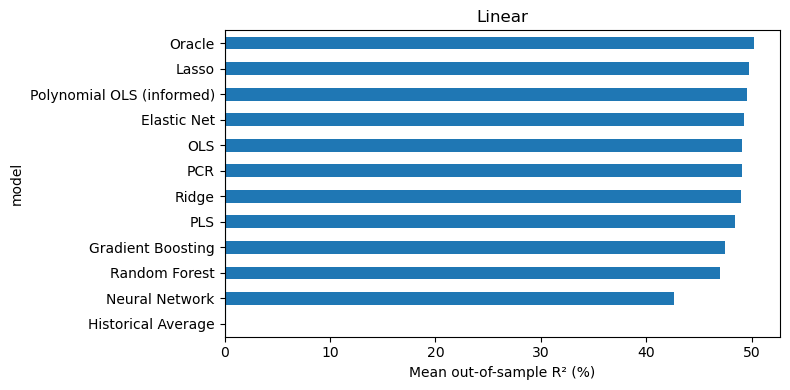

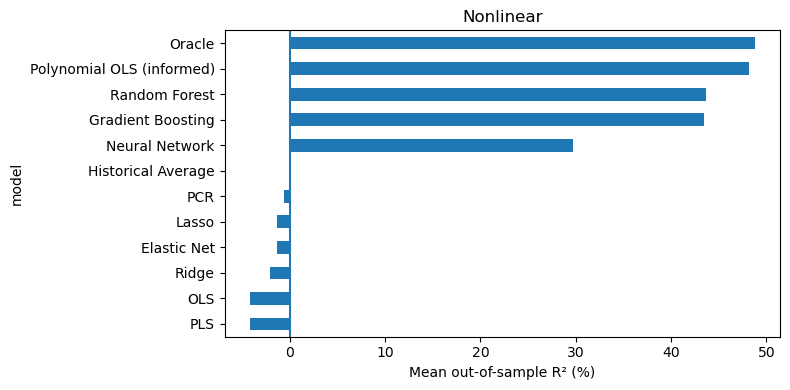

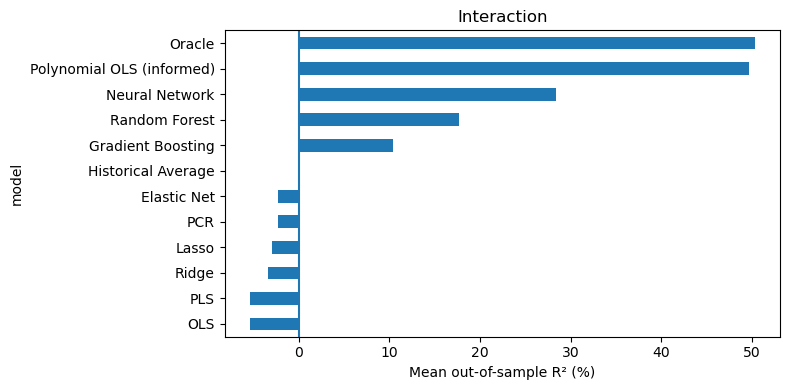

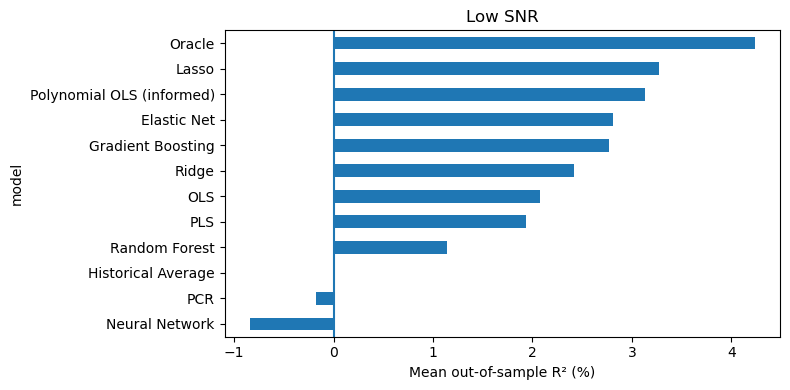

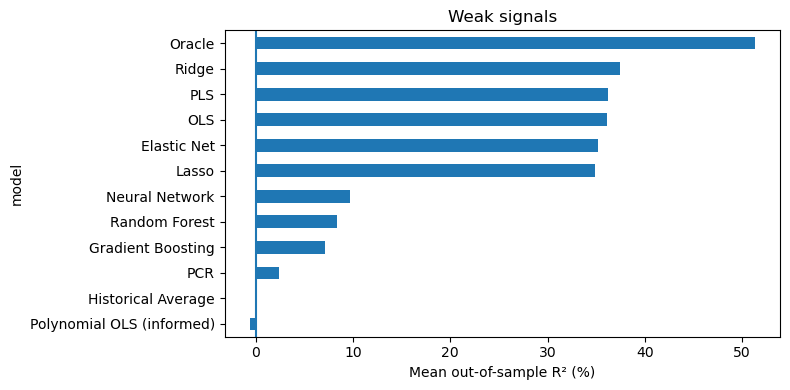

In [6]:
for s in SCENARIOS:
    fig,ax=plt.subplots(figsize=(8,4)); table.loc[s].sort_values().plot.barh(ax=ax); ax.axvline(0); ax.set(title=s,xlabel='Mean out-of-sample R² (%)'); plt.tight_layout(); plt.show()

## 5. Stability
重复次数较少时仅供课堂演示，不作显著性推断。

In [7]:
stability=results.groupby(['scenario','model']).R2_OS.agg(mean='mean',std='std',win_rate=lambda x:(x>0).mean())
display((100*stability).round(2))
display(results.groupby(['scenario','model']).Signal_MSE.mean().unstack().reindex(SCENARIOS).round(3))

mean    std  win_rate
scenario     model                                            
Interaction  Elastic Net                -2.25   1.73       0.0
             Gradient Boosting          10.39   3.63     100.0
             Historical Average          0.00   0.00       0.0
             Lasso                      -2.91   2.32       0.0
             Neural Network             28.36  10.09     100.0
             OLS                        -5.39   2.36       0.0
             Oracle                     50.30   3.25     100.0
             PCR                        -2.28   3.19      20.0
             PLS                        -5.38   2.36       0.0
             Polynomial OLS (informed)  49.72   3.60     100.0
             Random Forest              17.69   8.18     100.0
             Ridge                      -3.37   2.12       0.0
Linear       Elastic Net                49.31   3.10     100.0
             Gradient Boosting          47.51   2.00     100.0
             Historical Average          0.00   0.00       0.0
             Lasso                      49.75   2.65     100.0
             Neural Network             42.65   3.35     100.0
             OLS                        49.05   3.36     100.0
             Oracle                     50.18   2.99     100.0
             PCR                        49.05   3.36     100.0
             PLS                        48.40   2.95     100.0
             Polynomial OLS (informed)  49.61   3.06     100.0
             Random Forest              46.97   1.94     100.0
             Ridge                      49.01   3.34     100.0
Low SNR      Elastic Net                 2.81   1.75     100.0
             Gradient Boosting           2.77   1.23     100.0
             Historical Average          0.00   0.00       0.0
             Lasso                       3.27   1.22     100.0
             Neural Network             -0.84   2.71      40.0
             OLS                         2.08   2.39      80.0
             Oracle                      4.24   1.89     100.0
             PCR                        -0.17   2.43      20.0
             PLS                         1.93   2.11      80.0
             Polynomial OLS (informed)   3.14   1.83     100.0
             Random Forest               1.14   1.43      80.0
             Ridge                       2.42   2.18      80.0
Nonlinear    Elastic Net                -1.34   1.50      20.0
             Gradient Boosting          43.44   5.70     100.0
             Historical Average          0.00   0.00       0.0
             Lasso                      -1.32   1.63      20.0
             Neural Network             29.70   6.70     100.0
             OLS                        -4.13   2.36       0.0
             Oracle                     48.77   6.11     100.0
             PCR                        -0.60   0.85      60.0
             PLS                        -4.19   2.28       0.0
             Polynomial OLS (informed)  48.14   6.65     100.0
             Random Forest              43.68   5.38     100.0
             Ridge                      -2.09   1.88       0.0
Weak signals Elastic Net                35.14   3.32     100.0
             Gradient Boosting           7.10   3.80     100.0
             Historical Average          0.00   0.00       0.0
             Lasso                      34.89   7.35     100.0
             Neural Network              9.68   4.75     100.0
             OLS                        36.13   6.53     100.0
             Oracle                     51.30   3.72     100.0
             PCR                         2.42   2.47     100.0
             PLS                        36.18   3.56     100.0
             Polynomial OLS (informed)  -0.60   0.87      20.0
             Random Forest               8.40   1.01     100.0
             Ridge                      37.48   3.09     100.0

model,Elastic Net,Gradient Boosting,Historical Average,Lasso,Neural Network,OLS,Oracle,PCR,PLS,Polynomial OLS (informed),Random Forest,Ridge
scenario,,,,,,,,,,,,
Linear,0.015,0.051,0.978,0.012,0.123,0.027,0.0,0.027,0.031,0.016,0.062,0.026
Nonlinear,0.924,0.095,0.904,0.922,0.305,0.978,0.0,0.909,0.978,0.016,0.094,0.940
Interaction,1.041,0.793,1.000,1.049,0.405,1.092,0.0,1.042,1.092,0.016,0.638,1.056
Low SNR,0.465,0.508,1.081,0.338,1.077,0.667,0.0,0.772,0.640,0.394,0.814,0.489
Weak signals,0.310,0.856,0.992,0.319,0.852,0.298,0.0,0.945,0.281,0.991,0.843,0.255


## 6. Discussion
- Linear：OLS 是否足够？
- Nonlinear / Interaction：灵活模型是否有优势？知道正确结构的传统模型呢？
- Low SNR：理论信号占总方差的 1/26，谁能稳定战胜均值？
- Weak signals：收缩还是变量选择？
- 真实数据没有 Oracle，如何判断模型学到的是信号还是噪声？

**Complexity is useful only when it improves prediction.**